In [ ]:
pip install kagglehub

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\zoed\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [ ]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [ ]:
df.head()

**1. Frequency Tables**

In [22]:
frequency_table = df.category.value_counts()
frequency_table.columns = ["Category", "Frequency"]
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [29]:
frequency_table = df.category.value_counts().sort_values(ascending=False)
top_5 = frequency_table.head(5)
top_5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

According to the frequency table, the five most frequently listed product categories are Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, and Bath & Body. The category “Sports & Outdoors” has the highest number of listings.

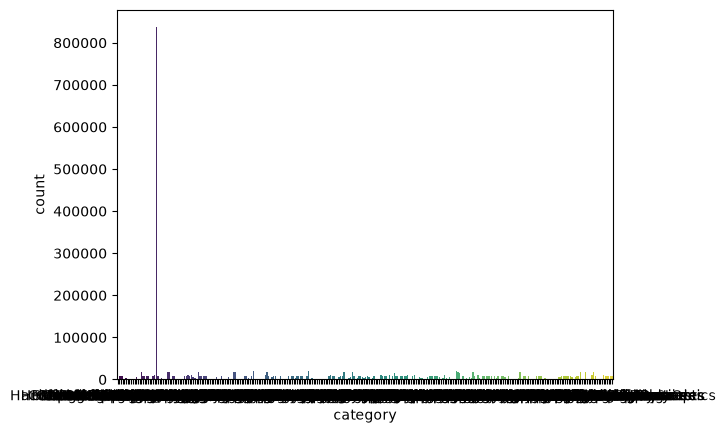

In [28]:
sns.countplot(
    x="category",
    data=df,
    hue="category",
    palette='viridis',
    legend=False,
)
plt.show()

Due to the large differences in frequency between the categories, the bar chart is difficult to read. Therefore, I will use a subset containing the five most frequently listed product categories.

In [39]:
top_cat = ["Sports & Outdoors", "Beauty", "Handmade Clothing, Shoes & Accessories", "Bath & Body", "Birthday Gifts"]
top_5_subset = df[df["category"].isin(top_cat)]
top_5_subset

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82165,89485,B08G2HBBB6,GoPro HERO9 - Waterproof Sports Camera with Fr...,4.5,5161,199.00,True,0,Sports & Outdoors
82166,89486,B09D15SFMQ,GoPro HERO10 Black - Waterproof Action Camera ...,4.4,2467,249.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


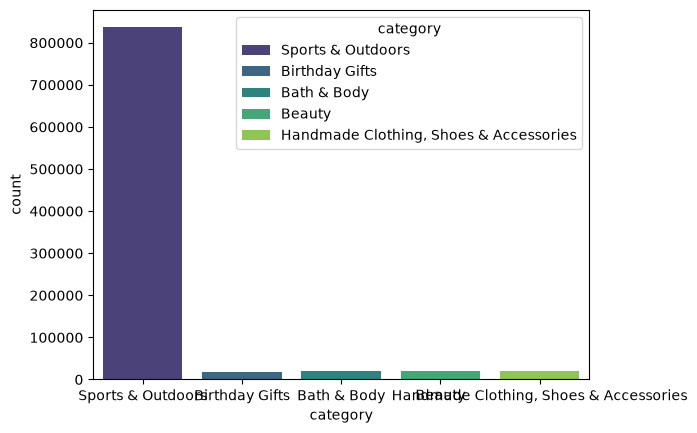

In [40]:
sns.countplot(
    x="category",
    data= top_5_subset,
    hue="category",
    palette='viridis',
    legend=True,
)
plt.show()

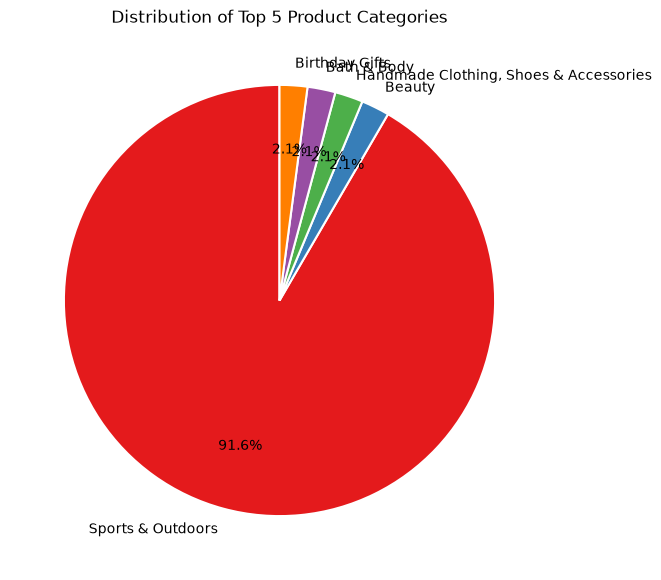

In [45]:
top_5.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set1'),
    figsize=(7, 7),
    pctdistance=0.7,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
)

plt.title("Distribution of Top 5 Product Categories")
plt.ylabel("")

plt.show()

The category "Sports & Outdoors" dominates the listing, as shown in the bar chart and the pie chart.

 2. Measurement of Centrality 

In [56]:
df_mean = df["stars"].mean()
df_median = df["stars"].median()
df_mode = df["stars"].mode()
print("mean:",df_mean, 
      "median:", df_median,
      "mode:", df_mode.tolist())

mean: 2.152836472966066 median: 0.0 mode: [0.0]


Customers seem to generally rate the products poorly, as the mean rating is relatively low, while both the median and mode are 0.

3. Measure of dispersion

In [60]:
df_var = df["stars"].var()
df_var
df["stars"].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

There is a wide variation in costumer feedback. The ratings show that customer feedback is generally quite low, with a median of 0 and an average of about 2.15. However, the upper 25% of ratings are above 4.4, indicating that a smaller group of customers gave very positive feedback.

4. Shape of the distribution

In [62]:
round(float(df["stars"].skew()), 2)

0.08

The skewness is 0.08, which is close to zero but positive. The distribution is slightly skewed to the right, with the bulk of the data points concentrated on the left and therefore leaning towards lower values. The ditribution is symmetric.

5. Visualisation

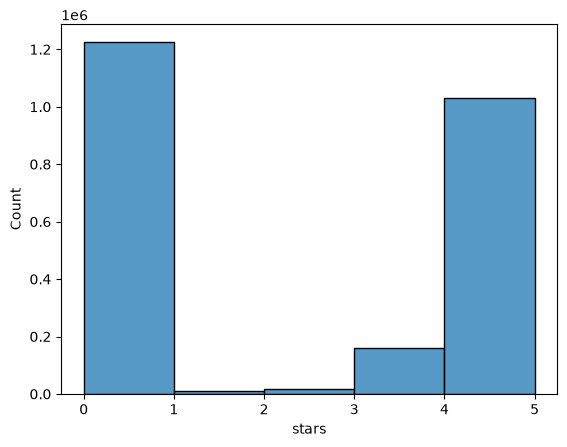

In [66]:
sns.histplot(df.stars, bins=5)
plt.show()

The distribution of the ratings is U-shaped, with a slight skew to the left. Very negative and very positive ratings are both very common. This suggests that customer experiences are highly polarized.